In [24]:
import usf
import numpy as np

import os
usf_folders = [#'/home/matt/geophysics_data/TEM/sTEM_data/2025_0227/USF_Files_dawa river/',
            #    '/home/matt/geophysics_data/TEM/sTEM_data/2025_0226/USF_Files_Dawa River Channel/',
            #    'E:/sTEM_data/2025_0302/USF_Files_dawa river 3/',
               'C:/Users/au646858/Downloads/2025_0622_profiler_sTEM53/USF_Files_profile_day_4_DD_Boren_Aliy_river/',
            #    '/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/'
               ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps
import pandas as pd

import plotly.graph_objects as go

fig = go.Figure()

in_use_hm = np.ones_like(hm.data, dtype=bool)
in_use_lm = np.ones_like(lm.data, dtype=bool)




# Combined data
fig.add_trace(go.Scatter(x=hm.time.mean(0), y=hm.data.mean(0), mode='lines+markers', name='High Mass Mean Combined', showlegend=False))
fig.add_trace(go.Scatter(x=lm.time.mean(0), y=lm.data.mean(0), mode='lines+markers', name='Low Mass Mean Combined', showlegend=False))

fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    xaxis_title="time [s]",
    yaxis_title="$\\frac{dB}{dt}$ \\[V / m$^2$\\]",
    margin=dict(t=30),
    dragmode='select',
)
fig

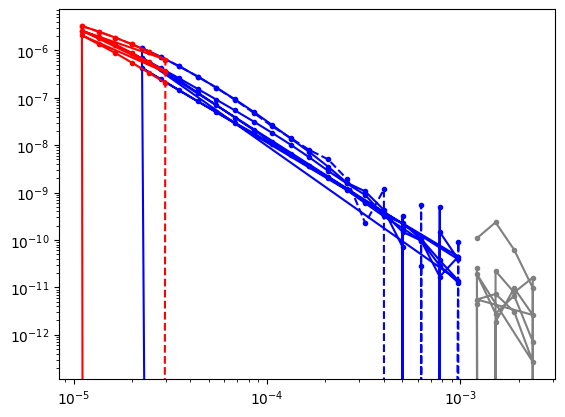

In [28]:
import matplotlib.pyplot as plt

hm_t, hm_d = hm.time[:5], hm.data[:5]
lm_t, lm_d = lm.time[:5], lm.data[:5]


lm_inuse = np.ones_like(lm_d, dtype=bool)
hm_inuse = np.ones_like(hm_d, dtype=bool)

hm_inuse[hm_t > 1e-3] = False
lm_inuse[lm_t > 1e-3] = False


plt.figure()
plt.loglog(hm_t[hm_inuse],  hm_d[hm_inuse], '.-', color='blue', label='High Mass')
plt.loglog(hm_t[hm_inuse], -hm_d[hm_inuse], '.--', color='blue', label='High Mass Negative')

plt.loglog(lm_t[lm_inuse],  lm_d[lm_inuse], '.-', color='red', label='Low Mass')
plt.loglog(lm_t[lm_inuse], -lm_d[lm_inuse], '.--', color='red', label='Low Mass Negative')

plt.plot(hm_t[~hm_inuse],  hm_d[~hm_inuse], '.-', color='gray', label='High Mass Disabled')
plt.plot(lm_t[~lm_inuse],  lm_d[~lm_inuse], '.-', color='gray', label='High Mass Disabled')

plt.plot(hm_t[~hm_inuse], -hm_d[~hm_inuse], '.-', color='gray', label='High Mass Disabled')
plt.plot(lm_t[~lm_inuse], -lm_d[~lm_inuse], '.-', color='gray', label='High Mass Disabled')
